In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python environment is ready!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python environment is ready!
Pandas version: 3.0.6
NumPy version: 2.5.4


age_group
18-34    1500.0
35-64    3850.0
65+      7800.0
Name: annual_expenditure, dtype: float64


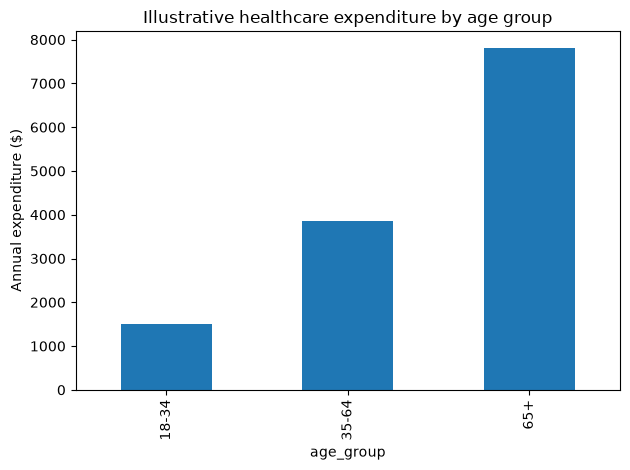

In [40]:
sample = pd.DataFrame({
    "age_group": ["18-34", "18-34", "35-64", "35-64", "65+"],
    "annual_expenditure": [1200, 1800, 3200, 4500, 7800]
})

summary = sample.groupby("age_group")["annual_expenditure"].mean()

print(summary)

summary.plot(kind="bar")
plt.ylabel("Annual expenditure ($)")
plt.title("Illustrative healthcare expenditure by age group")
plt.tight_layout()
plt.show()

In [41]:
from pathlib import Path

data_folder = Path.home() / "Documents" / "health-cost-analysis" / "data"

print("Files in data folder:")
for file in data_folder.iterdir():
    print(file.name)

Files in data folder:
PUFID.csv
h256dta.zip


In [42]:
import pandas as pd

file_path = data_folder / "h256dta.zip"
df = pd.read_stata(file_path)

print("Dataset dimensions:", df.shape)
display(df.head())

Dataset dimensions: (19140, 1615)


,DUID,PID,DUPERSID,PANEL,DATAYEAR,FAMID31,FAMID42,FAMID53,FAMID24,FAMIDYR,...,RXOTH24,PERWT24F,FAMWT24F,FAMWT24C,VARSTR,VARPSU,SAQWT24F,CSAQW24F,ESAQWT24F,PESAQWT24F
0,2810003,101,2810003101,28 PANEL 28,2024 YEAR,A,A,A,A,A,...,0,16532.179401,14481.891794,14481.891794,2062,1,19220.259043,0.0,19419.845142,22951.575300
1,2810006,101,2810006101,28 PANEL 28,2024 YEAR,A,A,A,A,A,...,0,41818.011780,44596.922708,44596.922708,2012,1,56091.114785,0.0,53136.862856,55108.036888
2,2810006,102,2810006102,28 PANEL 28,2024 YEAR,A,A,A,A,A,...,0,31330.068633,44596.922708,44596.922708,2012,1,48905.537993,0.0,53953.868356,56373.565367
3,2810006,103,2810006103,28 PANEL 28,2024 YEAR,A,A,A,A,A,...,0,47067.704703,44596.922708,44596.922708,2012,1,0.000000,0.0,0.000000,0.000000
4,2810006,104,2810006104,28 PANEL 28,2024 YEAR,A,A,A,A,A,...,0,33240.146510,44596.922708,44596.922708,2012,1,64420.763838,0.0,86534.512832,77577.353499


In [43]:
# Display column names related to medical spending
keywords = ["TOTEXP", "TOTSLF", "TOTPRV", "TOTMCR",
            "TOTMCD", "RXEXP", "AGE", "SEX", "REGION",
            "INSUR", "RTHLTH"]

for col in df.columns:
    if any(keyword in col.upper() for keyword in keywords):
        print(col)

REGION31
REGION42
REGION53
REGION24
AGE31X
AGE42X
AGE53X
AGE24X
AGELAST
SEX
HIBPAGED
CHDAGED
ANGIAGED
MIAGED
OHRTAGED
STRKAGED
EMPHAGED
CHOLAGED
DIABAGED
ARTHAGED
ASTHAGED
ADHDAGED
RTHLTH31
RTHLTH42
RTHLTH53
ADSEX42
ADAGE42_M24
ADMINSEXER42
CJWAGE42
WAGEP24X
INSURC24
TOTEXP24
TOTSLF24
TOTMCR24
TOTMCD24
TOTPRV24
OPSEXP24
VISEXP24
RXEXP24


In [44]:
print("Number of people:", len(df))
print("Number of variables:", len(df.columns))

# Show columns with the most missing values
missing = df.isna().mean().sort_values(ascending=False)
print(missing.head(15))

Number of people: 19140
Number of variables: 1615
DUID        0.0
PID         0.0
DUPERSID    0.0
PANEL       0.0
DATAYEAR    0.0
FAMID31     0.0
FAMID42     0.0
FAMID53     0.0
FAMID24     0.0
FAMIDYR     0.0
CPSFAMID    0.0
FCSZ1231    0.0
FCRP1231    0.0
RULETR31    0.0
RULETR42    0.0
dtype: float64


In [45]:
key_vars = [
    "AGELAST",
    "SEX",
    "REGION24",
    "INSURC24",
    "TOTEXP24",
    "TOTSLF24",
    "TOTPRV24",
    "TOTMCR24",
    "TOTMCD24",
    "RXEXP24",
    "PERWT24F",
]

# Keep only variables that exist in your dataset
key_vars = [col for col in key_vars if col in df.columns]

print(df[key_vars].dtypes)
display(df[key_vars].describe().T)

AGELAST         int8
SEX         category
REGION24    category
INSURC24    category
TOTEXP24       int32
TOTSLF24       int32
TOTPRV24       int32
TOTMCR24       int32
TOTMCD24       int32
RXEXP24        int32
PERWT24F     float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
AGELAST,19140.0,44.275235,24.167268,0.0,24.000000,45.000000,65.000000,8.500000e+01
TOTEXP24,19140.0,9333.040125,26992.443301,0.0,351.750000,2021.500000,7927.250000,1.246195e+06
TOTSLF24,19140.0,1187.474869,4779.069311,0.0,0.000000,200.000000,993.000000,3.179420e+05
TOTPRV24,19140.0,3389.824138,16091.592128,0.0,0.000000,154.000000,1591.000000,7.970130e+05
TOTMCR24,19140.0,3034.022884,13251.714570,0.0,0.000000,0.000000,290.250000,4.910730e+05
TOTMCD24,19140.0,1205.593208,12336.721341,0.0,0.000000,0.000000,0.000000,1.242405e+06
RXEXP24,19140.0,2404.379676,16241.502984,0.0,0.000000,44.000000,522.000000,1.188795e+06
PERWT24F,19140.0,17753.272184,11767.208710,0.0,9712.756419,15250.498183,23119.492302,9.125676e+04


In [46]:
import numpy as np
import pandas as pd

analysis_df = df[
    ["AGELAST", "TOTEXP24", "PERWT24F"]
].copy()

# Ensure numeric data
for col in ["AGELAST", "TOTEXP24", "PERWT24F"]:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors="coerce"
    )

# Remove invalid or missing records
analysis_df = analysis_df.dropna(
    subset=["AGELAST", "TOTEXP24", "PERWT24F"]
)

analysis_df = analysis_df[
    (analysis_df["AGELAST"] >= 0) &
    (analysis_df["TOTEXP24"] >= 0) &
    (analysis_df["PERWT24F"] > 0)
].copy()

# Group by age
analysis_df["AGE_GROUP"] = pd.cut(
    analysis_df["AGELAST"],
    bins=[-1, 17, 34, 49, 64, 120],
    labels=["0–17", "18–34", "35–49", "50–64", "65+"]
)

# Summarize expenditure by age group
results = (
    analysis_df.groupby("AGE_GROUP", observed=False)
    .apply(
        lambda g: pd.Series({
            "PEOPLE_IN_SAMPLE": len(g),
            "WEIGHTED_AVG_EXPENDITURE": (
                np.average(g["TOTEXP24"], weights=g["PERWT24F"])
                if len(g) > 0 else np.nan
            ),
            "UNWEIGHTED_AVG_EXPENDITURE": g["TOTEXP24"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

display(results.round(2))


,AGE_GROUP,PEOPLE_IN_SAMPLE,WEIGHTED_AVG_EXPENDITURE,UNWEIGHTED_AVG_EXPENDITURE
0,0–17,3557.0,3629.75,3479.55
1,18–34,3163.0,4645.64,4631.52
2,35–49,3361.0,7375.44,7532.95
3,50–64,3652.0,11883.20,12564.17
4,65+,4950.0,15737.63,15935.64


In [47]:
import numpy as np
import pandas as pd

analysis_df = df[
    ["AGELAST", "TOTEXP24", "PERWT24F"]
].copy()

# Convert columns to numeric where necessary
for col in ["AGELAST", "TOTEXP24", "PERWT24F"]:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors="coerce"
    )

# Keep valid ages, expenditures, and positive survey weights
analysis_df = analysis_df.dropna(
    subset=["AGELAST", "TOTEXP24", "PERWT24F"]
)

analysis_df = analysis_df[
    (analysis_df["AGELAST"] >= 0) &
    (analysis_df["PERWT24F"] > 0) &
    (analysis_df["TOTEXP24"] >= 0)
].copy()

# Create age groups
analysis_df["AGE_GROUP"] = pd.cut(
    analysis_df["AGELAST"],
    bins=[-1, 17, 34, 49, 64, 120],
    labels=["0–17", "18–34", "35–49", "50–64", "65+"]
)

# Calculate weighted expenditure by age group
results = (
    analysis_df.groupby("AGE_GROUP", observed=False)
    .apply(
        lambda g: np.average(
            g["TOTEXP24"],
            weights=g["PERWT24F"]
        ) if len(g) > 0 else np.nan,
        include_groups=False
    )
    .rename("WEIGHTED_AVG_EXPENDITURE")
    .reset_index()
)

display(results)

,AGE_GROUP,WEIGHTED_AVG_EXPENDITURE
0,0–17,3629.749264
1,18–34,4645.643988
2,35–49,7375.436368
3,50–64,11883.200198
4,65+,15737.629370


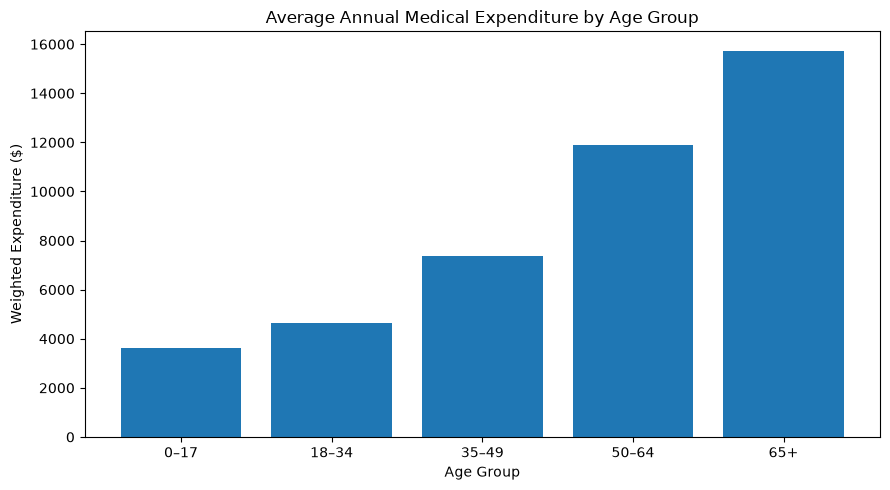

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    results["AGE_GROUP"].astype(str),
    results["WEIGHTED_AVG_EXPENDITURE"]
)
plt.title("Average Annual Medical Expenditure by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Weighted Expenditure ($)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [49]:
# Inspect insurance coverage categories and sample counts
print(df["INSURC24"].value_counts(dropna=False))

# Inspect the expenditure variable
print(df["TOTEXP24"].describe())

INSURC24
1 <65 ANY PRIVATE                           9080
2 <65 PUBLIC ONLY                           3793
4 65+ EDITED MEDICARE ONLY                  2140
5 65+ EDITED MEDICARE AND PRIVATE           1891
3 <65 UNINSURED                             1270
6 65+ EDITED MEDICARE AND OTH PUB ONLY       881
8 65+ NO MEDICARE AND ANY PUBLIC/PRIVATE      67
7 65+ UNINSURED                               18
Name: count, dtype: int64
count    1.914000e+04
mean     9.333040e+03
std      2.699244e+04
min      0.000000e+00
25%      3.517500e+02
50%      2.021500e+03
75%      7.927250e+03
max      1.246195e+06
Name: TOTEXP24, dtype: float64


In [50]:
import numpy as np
import pandas as pd

cols = ["INSURC24", "TOTEXP24", "PERWT24F"]
ins_df = df[cols].copy()

ins_df["TOTEXP24"] = pd.to_numeric(
    ins_df["TOTEXP24"], errors="coerce"
)
ins_df["PERWT24F"] = pd.to_numeric(
    ins_df["PERWT24F"], errors="coerce"
)

ins_df = ins_df.dropna(subset=cols)
ins_df = ins_df[
    (ins_df["TOTEXP24"] >= 0) &
    (ins_df["PERWT24F"] > 0)
]

summary = []

for category, group in ins_df.groupby("INSURC24", observed=True):
    weights = group["PERWT24F"]
    costs = group["TOTEXP24"]

    summary.append({
        "INSURANCE_CATEGORY": str(category),
        "SAMPLE_SIZE": len(group),
        "WEIGHTED_AVG_EXPENDITURE": np.average(
            costs, weights=weights
        ),
        "MEDIAN_EXPENDITURE": costs.median(),
        "ZERO_EXPENDITURE_PCT": (
            costs.eq(0).mean() * 100
        ),
        "WEIGHTED_POPULATION_ESTIMATE": weights.sum()
    })

insurance_results = pd.DataFrame(summary)

insurance_results = insurance_results.sort_values(
    "WEIGHTED_AVG_EXPENDITURE", ascending=False
)

display(insurance_results.round(2))

,INSURANCE_CATEGORY,SAMPLE_SIZE,WEIGHTED_AVG_EXPENDITURE,MEDIAN_EXPENDITURE,ZERO_EXPENDITURE_PCT,WEIGHTED_POPULATION_ESTIMATE
5,6 65+ EDITED MEDICARE AND OTH PUB ONLY,869,18014.88,8226.0,3.45,9.218140e+06
4,5 65+ EDITED MEDICARE AND PRIVATE,1879,17789.34,7241.0,1.60,2.539667e+07
3,4 65+ EDITED MEDICARE ONLY,2121,13415.89,5647.0,4.48,2.780927e+07
7,8 65+ NO MEDICARE AND ANY PUBLIC/PRIVATE,66,10476.83,3331.0,9.09,1.027322e+06
0,1 <65 ANY PRIVATE,8889,7126.98,1769.0,11.25,1.933589e+08
1,2 <65 PUBLIC ONLY,3653,7086.21,827.0,17.99,6.099107e+07
6,7 65+ UNINSURED,15,1859.71,418.0,46.67,2.254102e+05
2,3 <65 UNINSURED,1191,1090.76,0.0,55.75,2.177081e+07


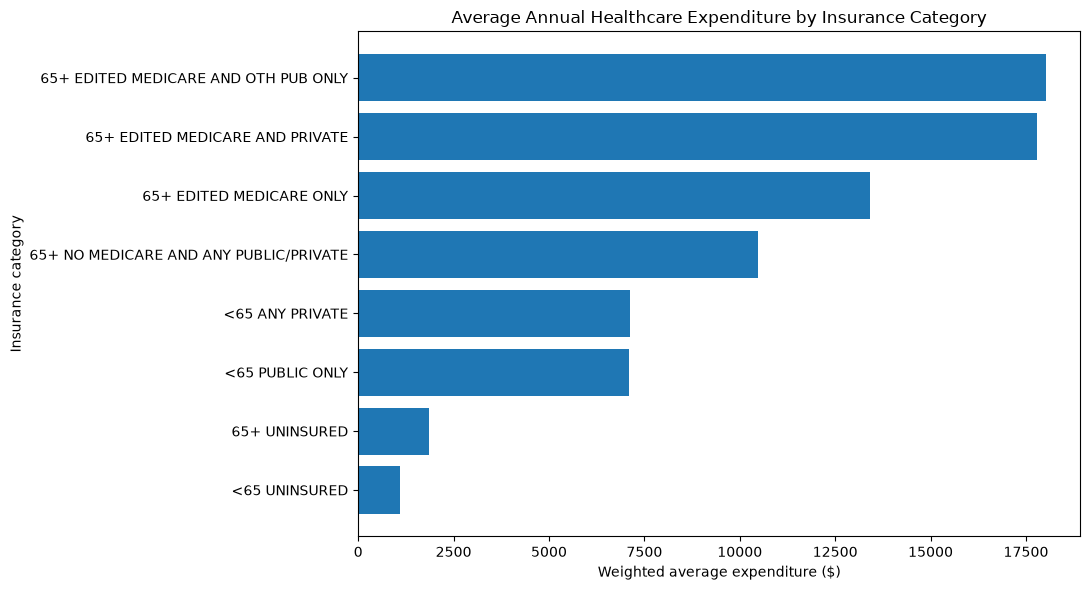

In [51]:
import matplotlib.pyplot as plt

chart_df = insurance_results.sort_values(
    "WEIGHTED_AVG_EXPENDITURE"
)

labels = [
    category.split(" ", 1)[1]
    for category in chart_df["INSURANCE_CATEGORY"]
]

plt.figure(figsize=(11, 6))
plt.barh(
    labels,
    chart_df["WEIGHTED_AVG_EXPENDITURE"]
)

plt.title(
    "Average Annual Healthcare Expenditure by Insurance Category"
)
plt.xlabel("Weighted average expenditure ($)")
plt.ylabel("Insurance category")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

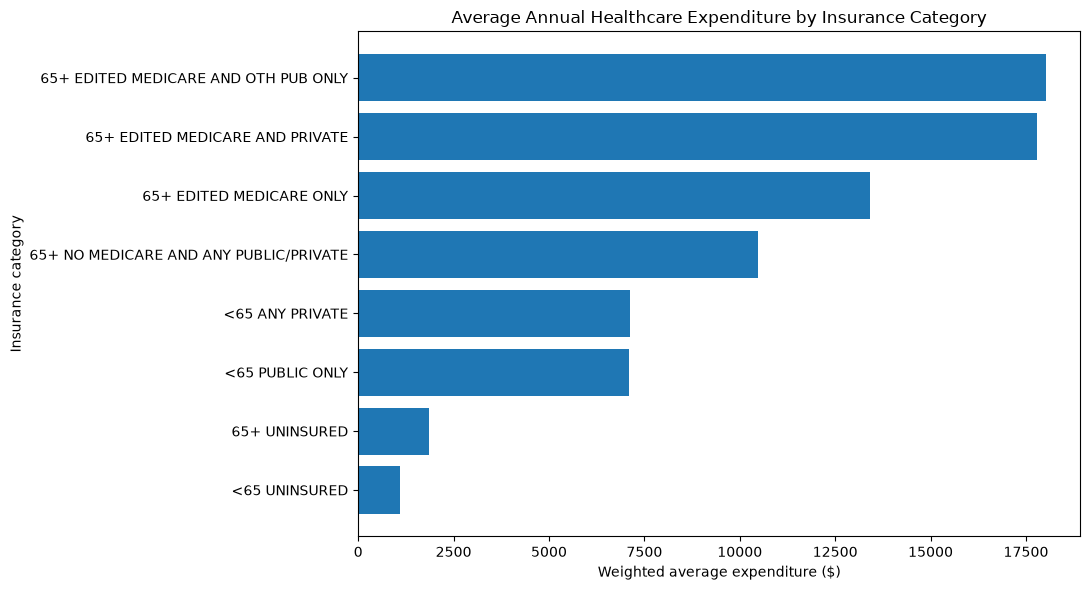

In [52]:
from pathlib import Path

output_folder = Path("../output")
output_folder.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(11, 6))
plt.barh(labels, chart_df["WEIGHTED_AVG_EXPENDITURE"])
plt.title("Average Annual Healthcare Expenditure by Insurance Category")
plt.xlabel("Weighted average expenditure ($)")
plt.ylabel("Insurance category")
plt.tight_layout()

plt.savefig(
    output_folder / "expenditure_by_insurance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [53]:
# Examine the distribution of total medical expenditure
percentiles = df["TOTEXP24"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Healthcare expenditure percentiles:")
display(percentiles.rename("EXPENDITURE").to_frame().round(2))

Healthcare expenditure percentiles:


,EXPENDITURE
0.50,2021.50
0.75,7927.25
0.90,22826.00
0.95,40169.05
0.99,107736.71


In [54]:
import numpy as np
import pandas as pd

cost_df = df[["TOTEXP24", "PERWT24F"]].copy()

cost_df["TOTEXP24"] = pd.to_numeric(
    cost_df["TOTEXP24"], errors="coerce"
)
cost_df["PERWT24F"] = pd.to_numeric(
    cost_df["PERWT24F"], errors="coerce"
)

cost_df = cost_df.dropna()
cost_df = cost_df[
    (cost_df["TOTEXP24"] >= 0) &
    (cost_df["PERWT24F"] > 0)
].copy()

# Rank people by expenditure
cost_df = cost_df.sort_values(
    "TOTEXP24", ascending=False
).reset_index(drop=True)

cost_df["WEIGHTED_COST"] = (
    cost_df["TOTEXP24"] * cost_df["PERWT24F"]
)

total_weighted_cost = cost_df["WEIGHTED_COST"].sum()
total_weight = cost_df["PERWT24F"].sum()

# Approximate population-weighted expenditure share
for top_pct in [0.01, 0.05, 0.10]:
    n = max(1, int(np.ceil(len(cost_df) * top_pct)))
    top_cost = cost_df.iloc[:n]["WEIGHTED_COST"].sum()

    print(
        f"Top {top_pct:.0%} of sample by expenditure: "
        f"{top_cost / total_weighted_cost:.1%} "
        "of weighted expenditure"
    )

Top 1% of sample by expenditure: 20.6% of weighted expenditure
Top 5% of sample by expenditure: 46.4% of weighted expenditure
Top 10% of sample by expenditure: 61.8% of weighted expenditure


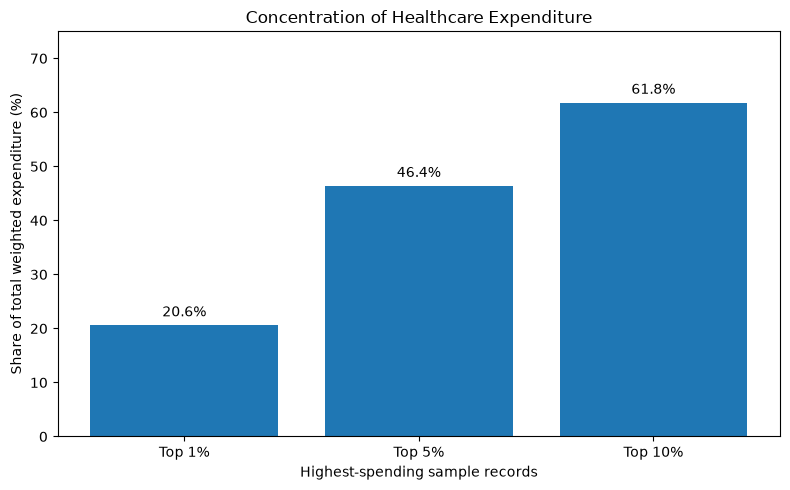

In [55]:
import matplotlib.pyplot as plt

top_percentages = [1, 5, 10]
spending_shares = [20.6, 46.4, 61.8]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    [f"Top {p}%" for p in top_percentages],
    spending_shares
)

plt.bar_label(
    bars,
    labels=[f"{s}%" for s in spending_shares],
    padding=4
)

plt.title("Concentration of Healthcare Expenditure")
plt.xlabel("Highest-spending sample records")
plt.ylabel("Share of total weighted expenditure (%)")
plt.ylim(0, 75)
plt.tight_layout()

plt.savefig(
    "../output/high_cost_spending_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# 1. Select the variables for modeling
features = ["AGELAST", "SEX", "REGION24", "INSURC24"]
target = "TOTEXP24"
weight_col = "PERWT24F"

model_df = df[features + [target, weight_col]].copy()

# Convert numeric variables
for col in ["AGELAST", target, weight_col]:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

# Remove records with invalid targets, ages, or weights
model_df = model_df.dropna(subset=[target, "AGELAST", weight_col])
model_df = model_df[
    (model_df[target] >= 0)
    & (model_df["AGELAST"] >= 0)
    & (model_df[weight_col] > 0)
].copy()

X = model_df[features]
y = model_df[target]
weights = model_df[weight_col]

# 2. Split before training to avoid evaluating on training records
X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, weights,
    test_size=0.20,
    random_state=42
)

# 3. Prepare numeric and categorical predictors
numeric_features = ["AGELAST"]
categorical_features = ["SEX", "REGION24", "INSURC24"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 4. Build the random forest regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Use MEPS person weights during model fitting
model.fit(X_train, y_train, regressor__sample_weight=w_train)

# 5. Predict on the held-out test set
predictions = np.maximum(model.predict(X_test), 0)

# Baseline: weighted training-set average for every test record
baseline_value = np.average(y_train, weights=w_train)
baseline_predictions = np.full(len(y_test), baseline_value)

# 6. Evaluate using survey-weighted metrics
def evaluate(actual, predicted, sample_weights):
    return {
        "Weighted MAE ($)": mean_absolute_error(
            actual, predicted, sample_weight=sample_weights
        ),
        "Weighted RMSE ($)": np.sqrt(mean_squared_error(
            actual, predicted, sample_weight=sample_weights
        )),
        "Weighted R-squared": r2_score(
            actual, predicted, sample_weight=sample_weights
        )
    }

metrics = pd.DataFrame({
    "Mean baseline": evaluate(y_test, baseline_predictions, w_test),
    "Random forest": evaluate(y_test, predictions, w_test)
}).T

print(f"Usable records: {len(model_df):,}")
print(f"Training records: {len(X_train):,}")
print(f"Test records: {len(X_test):,}")
print(f"Baseline prediction: ${baseline_value:,.2f}")
display(metrics.round(3))

# 7. Save reproducible project outputs
output_folder = Path("../output")
output_folder.mkdir(parents=True, exist_ok=True)

metrics.to_csv(output_folder / "model_evaluation.csv")

test_results = pd.DataFrame({
    "ACTUAL_EXPENDITURE": y_test.to_numpy(),
    "PREDICTED_EXPENDITURE": predictions,
    "PERSON_WEIGHT": w_test.to_numpy()
})

test_results.to_csv(
    output_folder / "test_predictions.csv",
    index=False
)

import joblib
joblib.dump(model, output_folder / "health_expenditure_model.joblib")

print(f"Results saved to: {output_folder.resolve()}")


Usable records: 18,683
Training records: 14,946
Test records: 3,737
Baseline prediction: $8,241.84


,Weighted MAE ($),Weighted RMSE ($),Weighted R-squared
Mean baseline,10698.374,25815.178,-0.000
Random forest,9971.631,25541.619,0.021


Results saved to: /Users/sammywu/Documents/health-cost-analysis/notebooks/output


,FEATURE,IMPORTANCE
0,numeric__AGELAST,0.6414
7,categorical__REGION24_4 WEST,0.0440
5,categorical__REGION24_2 MIDWEST,0.0428
1,categorical__SEX_1 MALE,0.0410
6,categorical__REGION24_3 SOUTH,0.0406
2,categorical__SEX_2 FEMALE,0.0400
9,categorical__INSURC24_2 <65 PUBLIC ONLY,0.0302
10,categorical__INSURC24_3 <65 UNINSURED,0.0292
8,categorical__INSURC24_1 <65 ANY PRIVATE,0.0252
4,categorical__REGION24_1 NORTHEAST,0.0213


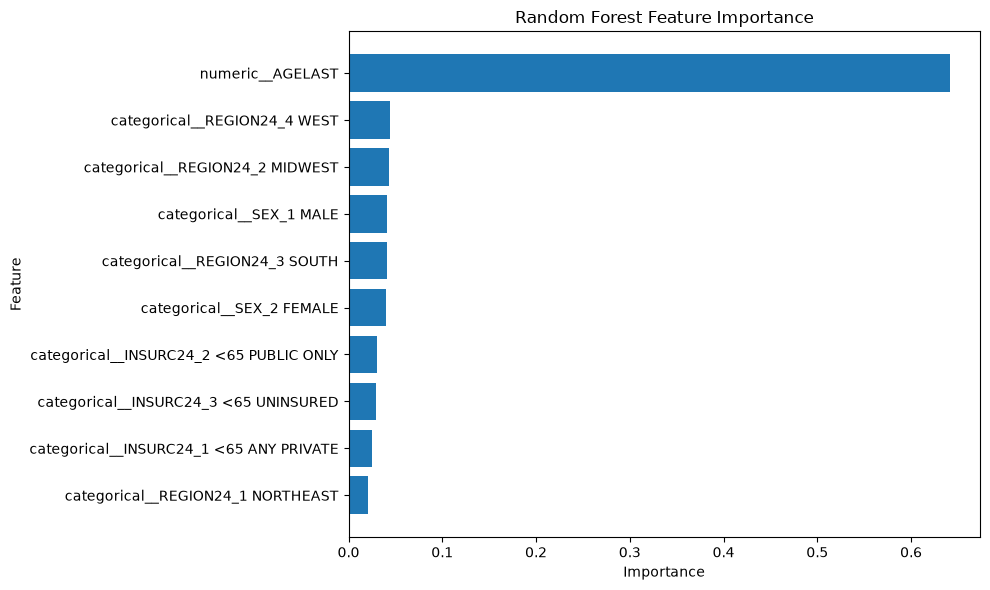

In [57]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature names after categorical encoding
preprocessor = model.named_steps["preprocessor"]
forest = model.named_steps["regressor"]

feature_names = preprocessor.get_feature_names_out()
importances = forest.feature_importances_

importance_df = pd.DataFrame({
    "FEATURE": feature_names,
    "IMPORTANCE": importances
}).sort_values("IMPORTANCE", ascending=False)

# Show the 15 most important encoded features
display(importance_df.head(15).round(4))

# Plot the 10 most important features
top_features = importance_df.head(10).sort_values("IMPORTANCE")

plt.figure(figsize=(10, 6))
plt.barh(top_features["FEATURE"], top_features["IMPORTANCE"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../output/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [58]:
# Inspect candidate health-status variables
health_vars = [
    "RTHLTH31",
    "RTHLTH42",
    "RTHLTH53",
    "AGE24X",
    "AGELAST",
    "INSURC24",
    "TOTEXP24",
]

for col in health_vars:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Data type:", df[col].dtype)
        print(df[col].value_counts(dropna=False).head(15))


--- RTHLTH31 ---
Data type: category
RTHLTH31
2 VERY GOOD        5876
3 GOOD             5277
1 EXCELLENT        4935
4 FAIR             2061
5 POOR              556
-1 INAPPLICABLE     389
-8 DON'T KNOW        23
-7 REFUSED           23
Name: count, dtype: int64

--- RTHLTH42 ---
Data type: category
RTHLTH42
2 VERY GOOD        6276
3 GOOD             5530
1 EXCELLENT        4639
4 FAIR             1931
5 POOR              456
-1 INAPPLICABLE     262
-7 REFUSED           29
-8 DON'T KNOW        17
Name: count, dtype: int64

--- RTHLTH53 ---
Data type: category
RTHLTH53
2 VERY GOOD        6424
3 GOOD             5513
1 EXCELLENT        4478
4 FAIR             1962
5 POOR              508
-1 INAPPLICABLE     211
-7 REFUSED           23
-8 DON'T KNOW        21
Name: count, dtype: int64

--- AGE24X ---
Data type: int8
AGE24X
85    434
67    339
63    307
68    299
66    297
64    296
72    292
69    284
70    279
65    275
73    271
62    267
39    264
58    262
71    262
Name: count, dty

In [59]:
# Create a cleaned health-status predictor
df["HEALTH_STATUS"] = (
    df["RTHLTH53"]
    .astype("string")
    .str.strip()
)

# Treat nonresponse and inapplicable codes as missing
invalid_codes = [
    "-1 INAPPLICABLE",
    "-7 REFUSED",
    "-8 DON'T KNOW"
]

df["HEALTH_STATUS"] = df["HEALTH_STATUS"].replace(
    invalid_codes, pd.NA
)

print(df["HEALTH_STATUS"].value_counts(dropna=False))


HEALTH_STATUS
2 VERY GOOD    6424
3 GOOD         5513
1 EXCELLENT    4478
4 FAIR         1962
5 POOR          508
<NA>            255
Name: count, dtype: Int64


/var/folders/1q/vhb96dzn2b97nskp0t4fw87m0000gn/T/ipykernel_21227/3392449478.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["HEALTH_STATUS"] = (


In [60]:
categorical_features = [
    "SEX",
    "REGION24",
    "INSURC24",
    "HEALTH_STATUS"
]


In [61]:
categorical_features = [
    "SEX",
    "REGION24",
    "INSURC24",
    "HEALTH_STATUS"
]

In [62]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define features and target
numeric_features = ["AGELAST"]

categorical_features = [
    "SEX",
    "REGION24",
    "INSURC24",
    "HEALTH_STATUS"
]

features = numeric_features + categorical_features
target = "TOTEXP24"
weight_col = "PERWT24F"

# 2. Prepare modeling data
model_df = df[features + [target, weight_col]].copy()

model_df[target] = pd.to_numeric(
    model_df[target], errors="coerce"
)
model_df[weight_col] = pd.to_numeric(
    model_df[weight_col], errors="coerce"
)

model_df = model_df[
    (model_df[target] >= 0) &
    (model_df["AGELAST"] >= 0) &
    (model_df[weight_col] > 0)
].copy()

# 3. Use the same split for both models
train_idx, test_idx = train_test_split(
    model_df.index,
    test_size=0.20,
    random_state=42
)

train = model_df.loc[train_idx]
test = model_df.loc[test_idx]

X_train = train[features]
X_test = test[features]
y_train = train[target]
y_test = test[target]
w_train = train[weight_col]
w_test = test[weight_col]

# 4. Build preprocessing pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# 5. Train model with health status
health_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

health_model.fit(
    X_train,
    y_train,
    regressor__sample_weight=w_train
)

# 6. Generate predictions
predictions = health_model.predict(X_test)

# 7. Evaluate with survey weights
weighted_mae = mean_absolute_error(
    y_test, predictions, sample_weight=w_test
)

weighted_rmse = np.sqrt(
    mean_squared_error(
        y_test, predictions, sample_weight=w_test
    )
)

weighted_r2 = r2_score(
    y_test, predictions, sample_weight=w_test
)

# 8. Print results
print("Records used:", len(model_df))
print("Training records:", len(train))
print("Testing records:", len(test))
print("\nRandom Forest with Health Status")
print(f"Weighted MAE:  ${weighted_mae:,.2f}")
print(f"Weighted RMSE: ${weighted_rmse:,.2f}")
print(f"Weighted R²:   {weighted_r2:.4f}")


TypeError: boolean value of NA is ambiguous

In [ ]:
# Convert health status to a standard object column
df["HEALTH_STATUS"] = (
    df["RTHLTH53"]
    .astype("object")
    .replace({
        "-1 INAPPLICABLE": np.nan,
        "-7 REFUSED": np.nan,
        "-8 DON'T KNOW": np.nan
    })
)

# Ensure pandas missing values become NumPy NaN
df["HEALTH_STATUS"] = df["HEALTH_STATUS"].where(
    df["HEALTH_STATUS"].notna(), np.nan
)

In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define features and target
numeric_features = ["AGELAST"]

categorical_features = [
    "SEX",
    "REGION24",
    "INSURC24",
    "HEALTH_STATUS"
]

features = numeric_features + categorical_features
target = "TOTEXP24"
weight_col = "PERWT24F"

# 2. Prepare modeling data
model_df = df[features + [target, weight_col]].copy()

model_df[target] = pd.to_numeric(
    model_df[target], errors="coerce"
)
model_df[weight_col] = pd.to_numeric(
    model_df[weight_col], errors="coerce"
)

model_df = model_df[
    (model_df[target] >= 0) &
    (model_df["AGELAST"] >= 0) &
    (model_df[weight_col] > 0)
].copy()

# 3. Use the same split for both models
train_idx, test_idx = train_test_split(
    model_df.index,
    test_size=0.20,
    random_state=42
)

train = model_df.loc[train_idx]
test = model_df.loc[test_idx]

X_train = train[features]
X_test = test[features]
y_train = train[target]
y_test = test[target]
w_train = train[weight_col]
w_test = test[weight_col]

# 4. Build preprocessing pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# 5. Train model with health status
health_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

health_model.fit(
    X_train,
    y_train,
    regressor__sample_weight=w_train
)

# 6. Generate predictions
predictions = health_model.predict(X_test)

# 7. Evaluate with survey weights
weighted_mae = mean_absolute_error(
    y_test, predictions, sample_weight=w_test
)

weighted_rmse = np.sqrt(
    mean_squared_error(
        y_test, predictions, sample_weight=w_test
    )
)

weighted_r2 = r2_score(
    y_test, predictions, sample_weight=w_test
)

# 8. Print results
print("Records used:", len(model_df))
print("Training records:", len(train))
print("Testing records:", len(test))
print("\nRandom Forest with Health Status")
print(f"Weighted MAE:  ${weighted_mae:,.2f}")
print(f"Weighted RMSE: ${weighted_rmse:,.2f}")
print(f"Weighted R²:   {weighted_r2:.4f}")


Records used: 18683
Training records: 14946
Testing records: 3737

Random Forest with Health Status
Weighted MAE:  $9,372.37
Weighted RMSE: $24,932.27
Weighted R²:   0.0668


In [ ]:

# Get transformed feature names and importance scores
feature_names = (
    health_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = health_model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "FEATURE": feature_names,
    "IMPORTANCE": importances
}).sort_values("IMPORTANCE", ascending=False)

# Display the top 15 individual features
print(importance_df.head(15).to_string(index=False))

# Summarize importance by original variable
importance_df["VARIABLE"] = importance_df["FEATURE"].str.split("__").str[-1]

importance_df["VARIABLE_GROUP"] = importance_df["FEATURE"].apply(
    lambda x: x.split("__")[0]
)

print("\nTop encoded features:")
print(importance_df.head(15).to_string(index=False))

print("\nImportance by feature type:")
print(
    importance_df.groupby("VARIABLE_GROUP")["IMPORTANCE"]
    .sum()
    .sort_values(ascending=False)
)


                                                FEATURE  IMPORTANCE
                                       numeric__AGELAST    0.475332
                      categorical__HEALTH_STATUS_5 POOR    0.173197
                      categorical__HEALTH_STATUS_4 FAIR    0.069045
                        categorical__REGION24_2 MIDWEST    0.040582
                              categorical__SEX_2 FEMALE    0.029323
                                categorical__SEX_1 MALE    0.029224
                          categorical__REGION24_3 SOUTH    0.028586
                categorical__INSURC24_1 <65 ANY PRIVATE    0.024026
categorical__INSURC24_5 65+ EDITED MEDICARE AND PRIVATE    0.020103
                           categorical__REGION24_4 WEST    0.019448
                      categorical__HEALTH_STATUS_3 GOOD    0.017708
                  categorical__INSURC24_3 <65 UNINSURED    0.012786
                      categorical__REGION24_1 NORTHEAST    0.012545
                categorical__INSURC24_2 <65 PUBL

In [ ]:

# Get transformed feature names and importance scores
feature_names = (
    health_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = health_model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "FEATURE": feature_names,
    "IMPORTANCE": importances
}).sort_values("IMPORTANCE", ascending=False)

# Display the top 15 individual features
print(importance_df.head(15).to_string(index=False))

# Summarize importance by original variable
importance_df["VARIABLE"] = importance_df["FEATURE"].str.split("__").str[-1]

importance_df["VARIABLE_GROUP"] = importance_df["FEATURE"].apply(
    lambda x: x.split("__")[0]
)

print("\nTop encoded features:")
print(importance_df.head(15).to_string(index=False))

print("\nImportance by feature type:")
print(
    importance_df.groupby("VARIABLE_GROUP")["IMPORTANCE"]
    .sum()
    .sort_values(ascending=False)
)


                                                FEATURE  IMPORTANCE
                                       numeric__AGELAST    0.475332
                      categorical__HEALTH_STATUS_5 POOR    0.173197
                      categorical__HEALTH_STATUS_4 FAIR    0.069045
                        categorical__REGION24_2 MIDWEST    0.040582
                              categorical__SEX_2 FEMALE    0.029323
                                categorical__SEX_1 MALE    0.029224
                          categorical__REGION24_3 SOUTH    0.028586
                categorical__INSURC24_1 <65 ANY PRIVATE    0.024026
categorical__INSURC24_5 65+ EDITED MEDICARE AND PRIVATE    0.020103
                           categorical__REGION24_4 WEST    0.019448
                      categorical__HEALTH_STATUS_3 GOOD    0.017708
                  categorical__INSURC24_3 <65 UNINSURED    0.012786
                      categorical__REGION24_1 NORTHEAST    0.012545
                categorical__INSURC24_2 <65 PUBL

In [ ]:

# Aggregate encoded feature importance by original predictor
importance_df = pd.DataFrame({
    "FEATURE": feature_names,
    "IMPORTANCE": importances
})

original_features = [
    "AGELAST",
    "HEALTH_STATUS",
    "REGION24",
    "SEX",
    "INSURC24"
]

def get_original_feature(feature_name):
    if feature_name.startswith("numeric__AGELAST"):
        return "AGELAST"

    for col in original_features:
        if feature_name.startswith(f"categorical__{col}_"):
            return col

    return "OTHER"

importance_df["ORIGINAL_FEATURE"] = (
    importance_df["FEATURE"].apply(get_original_feature)
)

summary_importance = (
    importance_df.groupby("ORIGINAL_FEATURE")["IMPORTANCE"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

summary_importance["IMPORTANCE_PCT"] = (
    summary_importance["IMPORTANCE"] * 100
).round(2)

print(summary_importance.to_string(index=False))


ORIGINAL_FEATURE  IMPORTANCE  IMPORTANCE_PCT
         AGELAST    0.475332           47.53
   HEALTH_STATUS    0.280308           28.03
        REGION24    0.106697           10.67
        INSURC24    0.079116            7.91
             SEX    0.058547            5.85


In [ ]:

from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

baseline_predictions = health_model.predict(X_test)
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions, sample_weight=w_test
)

results = []

for feature in X_test.columns:
    mae_increases = []

    for _ in range(10):
        X_permuted = X_test.copy()
        X_permuted[feature] = rng.permutation(
            X_permuted[feature].to_numpy()
        )

        permuted_predictions = health_model.predict(X_permuted)
        permuted_mae = mean_absolute_error(
            y_test,
            permuted_predictions,
            sample_weight=w_test
        )

        mae_increases.append(permuted_mae - baseline_mae)

    results.append({
        "FEATURE": feature,
        "MAE_INCREASE": np.mean(mae_increases),
        "MAE_INCREASE_PCT": (
            np.mean(mae_increases) / baseline_mae * 100
        )
    })

permutation_df = pd.DataFrame(results).sort_values(
    "MAE_INCREASE", ascending=False
)

print(permutation_df.to_string(index=False))


      FEATURE  MAE_INCREASE  MAE_INCREASE_PCT
HEALTH_STATUS   1587.976200         16.943158
      AGELAST   1193.893344         12.738430
     INSURC24    168.993472          1.803102
     REGION24    122.486622          1.306890
          SEX     36.916041          0.393881


In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare the modeling dataset
baseline_features = ["AGELAST", "SEX", "REGION24", "INSURC24"]
expanded_features = baseline_features + ["HEALTH_STATUS"]
required_columns = expanded_features + ["TOTEXP24", "PERWT24F"]

data = df[required_columns].copy()

data["TOTEXP24"] = pd.to_numeric(data["TOTEXP24"], errors="coerce")
data["PERWT24F"] = pd.to_numeric(data["PERWT24F"], errors="coerce")
data["AGELAST"] = pd.to_numeric(data["AGELAST"], errors="coerce")

# Exclude rows without a valid target or positive person weight
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["TOTEXP24", "PERWT24F"])
data = data[data["PERWT24F"] > 0].copy()

# Normalize categorical columns for sklearn's imputers
categorical_features = ["SEX", "REGION24", "INSURC24", "HEALTH_STATUS"]

for col in categorical_features:
    data[col] = data[col].astype(object)
    data[col] = data[col].where(data[col].notna(), np.nan)


# 2. Build a reusable model pipeline
def build_model(features):
    numeric_features = ["AGELAST"]
    categorical = [col for col in features if col in categorical_features]

    preprocessor = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        ))
    ])


# 3. Compare both models across five random splits
results = []

for seed in [21, 42, 63, 84, 105]:
    train_idx, test_idx = train_test_split(
        data.index, test_size=0.20, random_state=seed
    )

    train = data.loc[train_idx]
    test = data.loc[test_idx]

    y_train = train["TOTEXP24"]
    y_test = test["TOTEXP24"]
    w_train = train["PERWT24F"]
    w_test = test["PERWT24F"]

    for model_name, features in [
        ("Baseline", baseline_features),
        ("With health status", expanded_features)
    ]:
        model = build_model(features)

        model.fit(
            train[features],
            y_train,
            regressor__sample_weight=w_train
        )

        predictions = model.predict(test[features])

        results.append({
            "SEED": seed,
            "MODEL": model_name,
            "WEIGHTED_MAE": mean_absolute_error(
                y_test, predictions, sample_weight=w_test
            ),
            "WEIGHTED_RMSE": np.sqrt(mean_squared_error(
                y_test, predictions, sample_weight=w_test
            )),
            "WEIGHTED_R2": r2_score(
                y_test, predictions, sample_weight=w_test
            )
        })

results_df = pd.DataFrame(results)

print("Performance by split:")
print(results_df.round(3).to_string(index=False))

print("\nAverage performance across splits:")
summary = results_df.groupby("MODEL")[
    ["WEIGHTED_MAE", "WEIGHTED_RMSE", "WEIGHTED_R2"]
].agg(["mean", "std"])

print(summary.round(3).to_string())


Performance by split:
 SEED              MODEL  WEIGHTED_MAE  WEIGHTED_RMSE  WEIGHTED_R2
   21           Baseline      9435.621      21010.352        0.005
   21 With health status      8940.833      20641.754        0.039
   42           Baseline      9971.631      25541.619        0.021
   42 With health status      9372.374      24932.271        0.067
   63           Baseline      9841.644      31708.317        0.002
   63 With health status      9144.403      30495.466        0.077
   84           Baseline      9404.046      21240.574       -0.012
   84 With health status      8909.397      20694.949        0.039
  105           Baseline     10174.776      25941.285        0.004
  105 With health status      9979.236      25733.467        0.020

Average performance across splits:
                   WEIGHTED_MAE          WEIGHTED_RMSE           WEIGHTED_R2       
                           mean      std          mean       std        mean    std
MODEL                                

In [ ]:

# Refit the expanded model on the seed-42 split
train_idx, test_idx = train_test_split(
    data.index, test_size=0.20, random_state=42
)

train = data.loc[train_idx]
test = data.loc[test_idx]

health_model = build_model(expanded_features)

health_model.fit(
    train[expanded_features],
    train["TOTEXP24"],
    regressor__sample_weight=train["PERWT24F"]
)

# Create a test-set prediction table
error_df = test[
    ["AGELAST", "TOTEXP24", "PERWT24F"]
].copy()

error_df["PREDICTED_EXPENDITURE"] = health_model.predict(
    test[expanded_features]
)

error_df["ERROR"] = (
    error_df["PREDICTED_EXPENDITURE"] - error_df["TOTEXP24"]
)

error_df["ABS_ERROR"] = error_df["ERROR"].abs()

# Define age and actual expenditure groups
error_df["AGE_GROUP"] = pd.cut(
    error_df["AGELAST"],
    bins=[-1, 17, 34, 49, 64, np.inf],
    labels=["0-17", "18-34", "35-49", "50-64", "65+"]
)

error_df["EXPENDITURE_GROUP"] = pd.cut(
    error_df["TOTEXP24"],
    bins=[-0.01, 0, 1000, 5000, 20000, np.inf],
    labels=[
        "$0", "$1-$1,000", "$1,001-$5,000",
        "$5,001-$20,000", "Over $20,000"
    ]
)

# Summarize weighted prediction performance by group
def summarize_errors(group):
    weights = group["PERWT24F"].to_numpy()

    return pd.Series({
        "SAMPLE_SIZE": len(group),
        "WEIGHTED_ACTUAL_AVG": np.average(
            group["TOTEXP24"], weights=weights
        ),
        "WEIGHTED_PREDICTED_AVG": np.average(
            group["PREDICTED_EXPENDITURE"], weights=weights
        ),
        "WEIGHTED_MAE": np.average(
            group["ABS_ERROR"], weights=weights
        ),
        "WEIGHTED_BIAS": np.average(
            group["ERROR"], weights=weights
        )
    })

age_errors = (
    error_df.groupby("AGE_GROUP", observed=True)
    .apply(summarize_errors, include_groups=False)
    .reset_index()
)

spending_errors = (
    error_df.groupby("EXPENDITURE_GROUP", observed=True)
    .apply(summarize_errors, include_groups=False)
    .reset_index()
)

print("Prediction errors by age group:")
print(age_errors.round(2).to_string(index=False))

print("\nPrediction errors by actual expenditure group:")
print(spending_errors.round(2).to_string(index=False))


Prediction errors by age group:
AGE_GROUP  SAMPLE_SIZE  WEIGHTED_ACTUAL_AVG  WEIGHTED_PREDICTED_AVG  WEIGHTED_MAE  WEIGHTED_BIAS
     0-17        728.0              3353.39                 3027.46       3726.16        -325.93
    18-34        627.0              4572.56                 4834.75       5583.65         262.19
    35-49        688.0              7441.72                 7242.92       8963.78        -198.81
    50-64        726.0             13413.88                10881.87      14022.45       -2532.02
      65+        968.0             17195.33                15848.48      16597.82       -1346.85

Prediction errors by actual expenditure group:
EXPENDITURE_GROUP  SAMPLE_SIZE  WEIGHTED_ACTUAL_AVG  WEIGHTED_PREDICTED_AVG  WEIGHTED_MAE  WEIGHTED_BIAS
               $0        516.0                 0.00                 4467.09       4467.09        4467.09
        $1-$1,000        897.0               426.17                 5417.96       4998.04        4991.78
    $1,001-$5,000      

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reuse the same train/test split
train_idx, test_idx = train_test_split(
    data.index, test_size=0.20, random_state=42
)
train = data.loc[train_idx]
test = data.loc[test_idx]

features = expanded_features

# Part 1: Predict probability of any expenditure
any_cost_train = (train["TOTEXP24"] > 0).astype(int)

classifier_pipeline = build_model(features)
classifier_pipeline.steps[-1] = (
    "regressor",
    RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )
)

classifier_pipeline.fit(
    train[features],
    any_cost_train,
    regressor__sample_weight=train["PERWT24F"]
)

prob_positive = classifier_pipeline.predict_proba(
    test[features]
)[:, 1]

# Part 2: Predict expenditure among people with positive spending
positive_train = train[train["TOTEXP24"] > 0].copy()

positive_model = build_model(features)
positive_model.fit(
    positive_train[features],
    positive_train["TOTEXP24"],
    regressor__sample_weight=positive_train["PERWT24F"]
)

predicted_positive_cost = positive_model.predict(test[features])

# Combine both parts to estimate unconditional expected expenditure
two_part_predictions = prob_positive * predicted_positive_cost

# Compare with the existing expanded model on the same test set
single_model = build_model(features)
single_model.fit(
    train[features],
    train["TOTEXP24"],
    regressor__sample_weight=train["PERWT24F"]
)

single_predictions = single_model.predict(test[features])

y_test = test["TOTEXP24"]
w_test = test["PERWT24F"]

def evaluate_model(name, predictions):
    return {
        "MODEL": name,
        "WEIGHTED_MAE": mean_absolute_error(
            y_test, predictions, sample_weight=w_test
        ),
        "WEIGHTED_RMSE": np.sqrt(mean_squared_error(
            y_test, predictions, sample_weight=w_test
        )),
        "WEIGHTED_R2": r2_score(
            y_test, predictions, sample_weight=w_test
        )
    }

comparison = pd.DataFrame([
    evaluate_model("Single random forest", single_predictions),
    evaluate_model("Two-part random forest", two_part_predictions)
])

print(comparison.round(3).to_string(index=False))


                 MODEL  WEIGHTED_MAE  WEIGHTED_RMSE  WEIGHTED_R2
  Single random forest      9372.374      24932.271        0.067
Two-part random forest      9324.223      24887.325        0.070


In [ ]:

# Compare model errors across actual expenditure groups
comparison_errors = test[
    ["TOTEXP24", "PERWT24F"]
].copy()

comparison_errors["SINGLE_PREDICTION"] = single_predictions
comparison_errors["TWO_PART_PREDICTION"] = two_part_predictions

comparison_errors["EXPENDITURE_GROUP"] = pd.cut(
    comparison_errors["TOTEXP24"],
    bins=[-0.01, 0, 1000, 5000, 20000, np.inf],
    labels=[
        "$0", "$1-$1,000", "$1,001-$5,000",
        "$5,001-$20,000", "Over $20,000"
    ]
)

rows = []

for group, subset in comparison_errors.groupby(
    "EXPENDITURE_GROUP", observed=True
):
    weights = subset["PERWT24F"].to_numpy()
    actual = subset["TOTEXP24"].to_numpy()

    for model_name, pred_col in [
        ("Single random forest", "SINGLE_PREDICTION"),
        ("Two-part random forest", "TWO_PART_PREDICTION")
    ]:
        predicted = subset[pred_col].to_numpy()

        rows.append({
            "EXPENDITURE_GROUP": str(group),
            "MODEL": model_name,
            "WEIGHTED_MAE": np.average(
                np.abs(predicted - actual), weights=weights
            ),
            "WEIGHTED_BIAS": np.average(
                predicted - actual, weights=weights
            )
        })

group_comparison = pd.DataFrame(rows)

print(group_comparison.round(2).to_string(index=False))


EXPENDITURE_GROUP                  MODEL  WEIGHTED_MAE  WEIGHTED_BIAS
               $0   Single random forest       4467.09        4467.09
               $0 Two-part random forest       4551.41        4551.41
        $1-$1,000   Single random forest       4998.04        4991.78
        $1-$1,000 Two-part random forest       5004.07        5000.90
    $1,001-$5,000   Single random forest       5494.14        5022.56
    $1,001-$5,000 Two-part random forest       5384.17        4971.68
   $5,001-$20,000   Single random forest       6749.79         690.60
   $5,001-$20,000 Two-part random forest       6519.90         505.21
     Over $20,000   Single random forest      43725.13      -42443.01
     Over $20,000 Two-part random forest      43874.84      -42677.27
